# HW #3 - Machine Learning (Regression)

Within this homework exercise I will be using the `CBP_TWQM_MAIN_WQ_2021_2026_surface.csv` dataset to compare different machine learning regression techniques.

I will be using guidance from the framework laid out in the `Regression_Examples.ipynb` file to help me.

In [14]:
%matplotlib inline 
# the line above is a command that configures Matplotlib to render plot images directly inside the Jupyter Notebook, beneath the code cell that generated them.
# we will need to have "scikit-learn" package installed in our local environment, after activating the environment (such as HW3)
# example (Windows): 
#    conda activate HW3
#    conda install scikit-learn -y
# more instructions if needed: https://scikit-learn.org/stable/install.html

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Linear model and basic functions from scikit-learn
from sklearn import datasets, linear_model
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

# Specific models we will use beyond linear regression from scikit-learn
from sklearn.neighbors import KNeighborsRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.neighbors import RadiusNeighborsRegressor

This should import all of the needed tools and packages for what I need to do for this assignment.

In [15]:
# Load in the csv file with Chesapeake Bay surface water quality data from 2021-2026.

# Set the path to the correct directory for your particular computer
infile = 'C:/Users/jtgal/OEAS805/DATA/CBP_TWQM_MAIN_WQ_2021_2026_surface.csv'

This data is Chesapeake Bay Program Water Quality data from 2021-2026 at station 4.1C in the upper mainstem Chesapeake Bay. This dataset is the cleaned version from what was used in class in the matplotlib_exercise.ipynb notebook, so that now it is only data from surface waters including all variables ("`Parameters`").

In [16]:
# Investigate the dataset a little

# List out all of the column headers in the dataset
headers = pd.read_csv(infile, nrows=0).columns.tolist()
print(headers)

df = pd.read_csv(infile, low_memory=False)

# Give info including data types and number of rows 
df.info()

['Station', 'FieldActivityId', 'Cruise', 'Program', 'Project', 'DataCollector', 'DataProvider', 'Latitude', 'Longitude', 'SampleDate', 'SampleTime', 'TotalDepthM', 'UpperPycnoclineDepthM', 'LowerPycnoclineDepthM', 'SampleDepthM', 'Layer', 'SampleType', 'SampleReplicate', 'Parameter', 'Qualifier', 'MeasureValue', 'MeasureUnit', 'Method', 'Lab', 'Problem', 'PrecisionPC', 'BiasPC', 'Details', 'TierLevel']
<class 'pandas.DataFrame'>
RangeIndex: 1223 entries, 0 to 1222
Data columns (total 29 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Station                1223 non-null   str    
 1   FieldActivityId        1223 non-null   int64  
 2   Cruise                 1223 non-null   str    
 3   Program                1223 non-null   str    
 4   Project                1223 non-null   str    
 5   DataCollector          1223 non-null   str    
 6   DataProvider           1223 non-null   str    
 7   Latitude               12

For the variables to be targeted and used as predictor variables, we will find these in the `Parameter` column (Column 18). Actual values and the units for those values can be found in `MeasureValue` (Column 20) and `MeasureUnit` (Column 21), respectively.

In [17]:
df["Parameter"].unique()

<StringArray>
[    'CHLA',      'DIN',       'DO',      'DON',      'DOP',       'KD',
     'NH4F',    'NO23F',     'NO2F',     'NO3F',       'PC',       'PH',
     'PHEO',       'PN',     'PO4F',       'PP', 'SALINITY',   'SECCHI',
  'SIGMA_T',   'SPCOND',      'TDN',      'TDP',       'TN',      'TON',
       'TP',      'TSS',    'WTEMP']
Length: 27, dtype: str

I am going to chose to predict `DO` (Dissolved Oxygen concentration) from this dataset. I want to us `Salinity`, `Water Temperature`, and `Chla` to help me try to predict DO. I chose these variables to help in predicting DO because they all have known impacts on the dissolved oxygen in water. Salinity and water temperature both have one direction influences whether they are high or low, while Chla has a dual impact, based on diurnal cycles. Increased salinity and water temperature both have negative impacts on the amount of dissolved oxygen that can be soluble in a water sample. Additionally, increased Chla concentration can have both a positive and negative effect on the dissolved oxygen concentration. This is because during the day photosynthesis increases the DO, but respiration and break down of dead organisms will take oxygen out of the water.

In [18]:
# Define parameter names and link them with their names from the dataset
parameters = {
    "Salinity": {"SALINITY"},
    "Water Temperature": {"WTEMP"},
    "Chla": {"CHLA"},
}

# Create a fast reverse lookup dictionary (Uppercase Alias -> Standard Name)
alias_to_name = {
    alias.upper(): standard_name 
    for standard_name, aliases in parameters.items() 
    for alias in aliases
}

# Add standardized parameter column to avoid case issues
df_clean = df.copy()
df_clean["StandardParameter"] = df_clean["Parameter"].str.upper().map(alias_to_name)

# Pivot predictor data using clean standard names
predictor_data = (
    df_clean[df_clean["StandardParameter"].notnull()]
    .pivot_table(
        index="FieldActivityId",
        columns="StandardParameter",
        values="MeasureValue",
        aggfunc="mean"
    )
    .reset_index()
)

# Create target_data from your original dataframe (assuming target parameter is "DO")
target_data = (
    df[df["Parameter"].str.upper() == "DO"]
    [["FieldActivityId", "MeasureValue"]]
    .rename(columns={"MeasureValue": "DO"})
    .groupby("FieldActivityId", as_index=False)["DO"]
    .mean()  # Handles cases where there might be multiple DO measurements per FieldActivityId
)

# Merge the above with target data
model_data = target_data.merge(predictor_data, on="FieldActivityId", how="inner")
model_data = model_data.dropna(subset=["DO", *parameters.keys()])

# Define predictors and target
X = model_data[list(parameters.keys())]       # Predictor data
y = model_data["DO"]                          # Target data

# Drop any sample depth columns from the final view/dataset
depth_cols = [col for col in model_data.columns if "depth" in col.lower()]
model_data_cleaned = model_data.drop(columns=depth_cols, errors="ignore")

# Display results without depth columns
with pd.option_context("display.max_rows", None, "display.max_columns", None):
    display(model_data_cleaned)

# Print out the number of samples in the dataset
print(f"Number of samples: {len(X)}")

,FieldActivityId,DO,Chla,Salinity,Water Temperature
0,608240,7.3,7.595,8.31,23.3
1,608260,10.4,17.444,9.33,12.8
2,608274,10.2,12.935,11.87,9.2
3,611589,11.9,20.292,9.33,6.6
4,621061,14.4,37.380,6.49,18.1
5,621092,8.2,17.088,10.37,24.0
6,624712,8.4,16.173,14.46,26.0
7,624741,8.1,3.524,16.49,18.1
8,624755,8.4,3.952,17.25,14.9
9,624768,10.0,6.515,16.49,9.8


Number of samples: 42


So this table above shows all of our individual samples together (DO, Chla, Salinity, and Water Temperature) all associated with the matching `FieldActivityID`. There are a total of 42 samples that we can put together for all of the variables.

Shape of X (predictors): (42, 3)
Shape of y (target): (42,)
Coefficients: {'Salinity': np.float64(-0.08384795305017502), 'Water Temperature': np.float64(-0.18143644871201456), 'Chla': np.float64(0.04671762384968274)}
Equation: -0.0838 * Salinity + -0.1814 * Water Temperature + 0.0467 * Chla
Mean squared error: 1.02
R-squared: 0.75


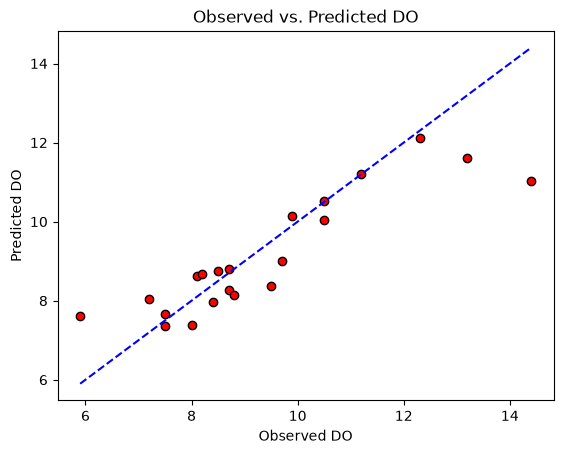

In [ ]:
# MULTIPLE LINEAR REGRESSION MODEL
# Print the shapes to show how many predictors (3) I have and how many rows of the target I am solving (42)
print("Shape of X (predictors):", X.shape)
print("Shape of y (target):", y.shape)

# Split the data into training and testing sets, setting size and setting random split for reproducibility
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.5, random_state=4) # 20% test, 80% train

# Fit a multiple linear regression model
regr = linear_model.LinearRegression()
regr.fit(X_train, y_train)

# Predict DO values for the test set
y_pred = regr.predict(X_test)

# Print metrics to evaluate model performance
print("Coefficients:", dict(zip(X.columns, regr.coef_))) # How much each predictor contributes to the model
equation_terms = [f"{coef:.4f} * {name}" for name, coef in zip(X.columns, regr.coef_)]
equation = " + ".join(equation_terms)
print("Equation:", equation)
print('Mean squared error: %.2f' % mean_squared_error(y_test, y_pred))
print("R-squared: %.2f" % r2_score(y_test, y_pred))

# Plot observed versus predicted DO values
plt.scatter(y_test, y_pred, color="red", edgecolor='k')
plot_limits = [
    min(y_test.min(), y_pred.min()),
    max(y_test.max(), y_pred.max())
]

# Setting the plot labels and title
plt.plot(plot_limits, plot_limits, "--", color="blue")
plt.xlabel("Observed DO")
plt.ylabel("Predicted DO")
plt.title("Observed vs. Predicted DO")
plt.show()

The Multiple Linear Regression (MLR) Model fit to the data fairly well (r^2 = 0.75), with the only data that it does not seem to be predicting well being the very lowest and especially the very highest observed data points. It looks to overpredict at the lowest values and underpredict at the higher values. Water temperature (-0.1814) and salinity (-0.0838) have negative influences as predicted from earlier. Chla concentration has a positive influence while have a low impact as far as magnitude (0.0467).

Hyperparameters For Multiple Linear Regression:
    Test Size: Set to 0.5 (50%) which determines that 50% of the data is used for testing and 50% for training
    Random State: Set to 4 which helped establish the correct reproducibility
*I chose these two parameters to be set to what they were because they resulted in the highest r^2 score of any combination of the two.*

R-squared score (k=6): 0.47


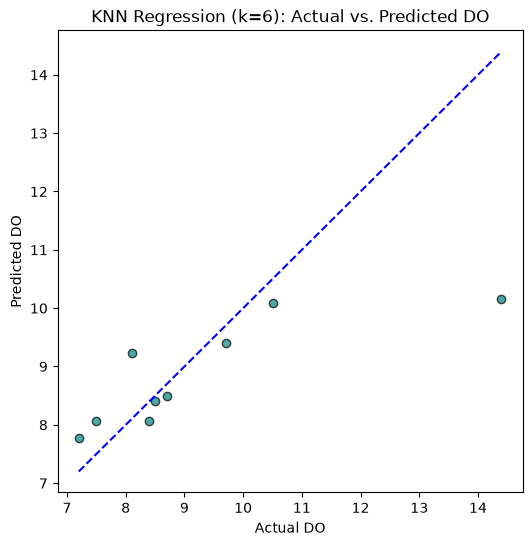

In [ ]:
# Choose the number of neighbors = 'k'
k = int(input('Choose a number for k: '))

# Split into train and test sets to properly evaluate generalization
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=4)

# Initiate and train the KNN regression model
model = KNeighborsRegressor(n_neighbors=k)
model.fit(X_train, y_train)

# Predict test data and compute the R-squared score
y_pred = model.predict(X_test)
print(f"R-squared score (k={k}): {r2_score(y_test, y_pred):.2f}")

# Plot the actual vs. predicted DO values for the KNN regression model
plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred, color='teal', edgecolor='k', alpha=0.7)

# Draw a reference line for a "perfect" prediction
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'b--', lw=1.5)

# Setting the plot labels and 
# title
plt.xlabel('Actual DO')
plt.ylabel('Predicted DO')
plt.title(f'KNN Linear Regression (k={k}): Actual vs. Predicted DO')
plt.show()

This predicts the dissolved oxygen values worse (r^2 = 0.47) than the multiple linear regression model. Again the model looks to overpredict on the lower end and underpredict at the higher values.

Hyperparameters For KNN Linear Regression:
    k: Set to 6 which gave the highest r^2 value. The k-value determines how many "neighbors" the model uses to predict the value. It is the best mix between underfitting (high k) and overfitting (low k).

Test R-squared score: 0.44
Test mean squared error: 2.39


Text(0.5, 1.0, 'MLP Regression (4 Hidden Nodes)')

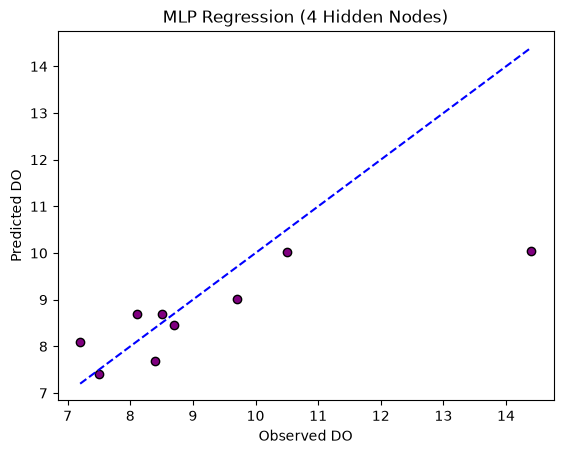

In [ ]:
# Bringing in 2 more libraries to help with the MLP regression model
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# Ask for the number of hidden nodes for the MLP model
n = int(input("Choose a number for hidden nodes: "))

# Fit the model with the specified number of hidden nodes
mlp_model = make_pipeline(
    StandardScaler(),
    MLPRegressor(
        hidden_layer_sizes=(n,),
        activation="relu",
        max_iter=10000,
        random_state=4
    )
)

# Fit the MLP model to the training data
mlp_model.fit(X_train, y_train)
y_pred_mlp = mlp_model.predict(X_test)

# Print out the descriptive statistics for the MLP model
print(f"Test R-squared score: {r2_score(y_test, y_pred_mlp):.2f}")
print(f"Test mean squared error: {mean_squared_error(y_test, y_pred_mlp):.2f}")

# Plot the actual vs. predicted DO values for the MLP regression model
plt.scatter(y_test, y_pred_mlp, color="purple", edgecolor="k")
plot_limits = [min(y_test.min(), y_pred_mlp.min()),
               max(y_test.max(), y_pred_mlp.max())]
plt.plot(plot_limits, plot_limits, "b--")
plt.xlabel("Observed DO")
plt.ylabel("Predicted DO")
plt.title(f"MLP Regression ({n} Hidden Nodes)")

This model, according to the r^2 (r^2 = 0.44), fit the model the worst of all of the machine learning models. Nowhere on the model does it look to follow the 1:1 trendline that would indicate a perfect model/actual fit.

Hyperparameters For MLP Regression:
    k: Set to 4 hidden nodes to get the highest r^2 value (r^2 = 0.44) and presumably the best fit.